# Day 17 | Teach the Answer Pattern With Examples

**KGP Talkie**

Use zero-shot, one-shot, and few-shot prompts on the same small task.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [2]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [3]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

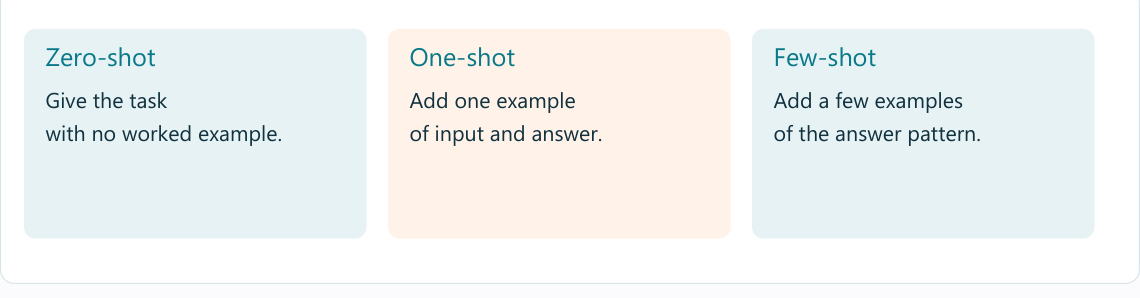

ChatOllama sends chat requests to the local Ollama server.

In [4]:
from langchain_ollama import ChatOllama

We keep tracing off for the local lesson. KGP_MODEL lets us choose another installed chat tag; llama3.2 is the tested default.

In [5]:
os.environ["LANGSMITH_TRACING"] = "false"
MODEL = os.getenv("KGP_MODEL", "llama3.2")

Temperature 0 reduces varied choices. The 128-token cap keeps this small task short; it does not guarantee correctness. localhost means this computer.

In [6]:
llm = ChatOllama(model=MODEL, temperature=0, num_predict=128, base_url="http://localhost:11434", client_kwargs={"timeout": 180})

In [7]:
task = "Label the text happy or unhappy. Return only the label.\nText: "

These examples guide the answer pattern within this request; no weights are trained.

In [8]:
examples = "Text: I liked the class. Label: happy\nText: The sound was unclear. Label: unhappy\n"

These sentences were not in the examples. Their known labels help us check the task.

In [9]:
tests = [("The class helped me.", "happy"), ("I could not hear the lesson.", "unhappy")]

The loop compares both prompt styles on the same inputs. Actual labels remain visible even if they are wrong.

In [10]:
for text, expected in tests:
    zero = llm.invoke(task + text).content.strip()
    few = llm.invoke(examples + task + text).content.strip()
    print({"text": text, "expected": expected, "zero_shot": zero, "few_shot": few})

{'text': 'The class helped me.', 'expected': 'happy', 'zero_shot': 'Happy', 'few_shot': 'happy'}


{'text': 'I could not hear the lesson.', 'expected': 'unhappy', 'zero_shot': 'Unhappy', 'few_shot': 'unhappy'}


In [11]:
mixed = "The slides were good but the sound was bad."

A mixed review shows why two labels may be too simple for some tasks.

In [12]:
print(llm.invoke(examples + task + mixed).content)

unhappy


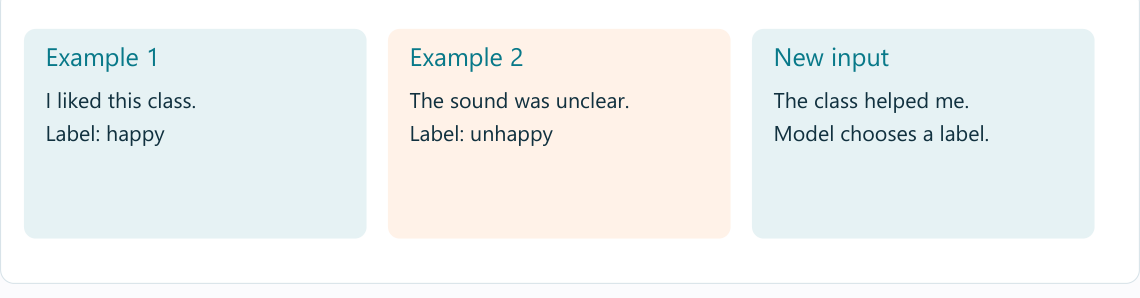

## Try a fresh input

Add a difficult sentence such as "The slides were good but the sound was bad." Check the limit of two labels.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/few-shot-prompting).